# Faster R-CNN Object Detection with PASCAL VOC 2007

This notebook demonstrates an end-to-end pipeline for training a Faster R-CNN object detection model using PyTorch and Torchvision. We cover downloading the dataset, preprocessing it, fine-tuning a pre-trained model, training with a custom loop, and running inference.

## Step 1: Data Acquisition
We downloaded the PASCAL VOC 2007 dataset using `torchvision.datasets`. We need a standard, well-annotated dataset to train our object detector. PASCAL VOC contains 20 common object classes, making it perfect for this tutorial.

In [ ]:
import torchvision
import os

# Create data directory
os.makedirs('./data', exist_ok=True)

# Download VOC 2007 trainval dataset
print("Downloading PASCAL VOC 2007 trainval dataset...")
voc_dataset = torchvision.datasets.VOCDetection(
    root='./data',
    year='2007',
    image_set='trainval',
    download=True
)

print(f"\nSuccessfully loaded dataset! Number of images: {len(voc_dataset)}")


Successfully loaded dataset! Number of images: 5011


### 1.1 Visualize the Data
We wrote a helper function to plot images with their ground-truth bounding boxes. It is crucial to verify that our dataset loaded correctly and that the bounding box annotations perfectly align with the objects before feeding them into a model.

Displaying image index: 229


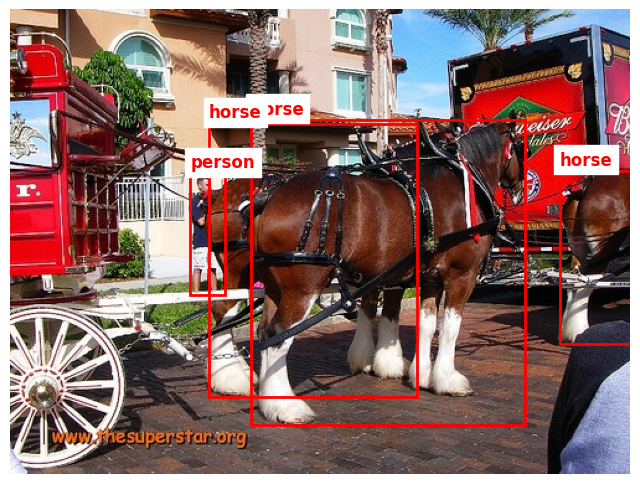

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import random

def plot_image_with_boxes(img, target):
    fig, ax = plt.subplots(1, figsize=(8, 8))
    ax.imshow(img)

    # Extract objects from the annotation dictionary
    objects = target['annotation']['object']
    if not isinstance(objects, list):
        objects = [objects] # Handle single object cases

    for obj in objects:
        bndbox = obj['bndbox']
        xmin = int(bndbox['xmin'])
        ymin = int(bndbox['ymin'])
        xmax = int(bndbox['xmax'])
        ymax = int(bndbox['ymax'])
        width = xmax - xmin
        height = ymax - ymin
        name = obj['name']

        # Create a rectangle patch
        rect = patches.Rectangle((xmin, ymin), width, height, linewidth=2, edgecolor='r', facecolor='none')
        ax.add_patch(rect)
        # Add label text
        ax.text(xmin, ymin - 5, name, color='red', fontsize=12, weight='bold', backgroundcolor='white')

    plt.axis('off')
    plt.show()

# Select a random image and visualize
idx = random.randint(0, len(voc_dataset) - 1)
img, target = voc_dataset[idx]
print(f"Displaying image index: {idx}")
plot_image_with_boxes(img, target)

## Step 2: Preprocessing and Data Loaders
We created a custom PyTorch `Dataset`, applied `torchvision.transforms.v2` for image augmentation, and built `DataLoader` instances. Neural networks require data in specific tensor formats. We also added data augmentation (like flipping and color jittering) to artificially expand our dataset and prevent the model from overfitting. The DataLoaders handle batching the images efficiently during training.

In [ ]:
import torch
from torch.utils.data import DataLoader, Subset
import numpy as np
import torchvision
from torchvision.transforms import v2
from torchvision import tv_tensors

# Define bounding-box aware transformations using torchvision v2
def get_transform(train=False):
    transforms = []
    if train:
        # v2 transforms automatically adjust bounding boxes when flipping
        transforms.append(v2.RandomHorizontalFlip(0.5))
        transforms.append(v2.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3, hue=0.05))
    transforms.append(v2.ToImage())
    transforms.append(v2.ToDtype(torch.float32, scale=True))
    transforms.append(v2.SanitizeBoundingBoxes()) # Removes degenerate boxes
    return v2.Compose(transforms)

# Custom dataset class to format the target
class VOCDatasetFormat(torch.utils.data.Dataset):
    def __init__(self, root, transforms=None):
        self.dataset = torchvision.datasets.VOCDetection(root, year='2007', image_set='trainval', download=False)
        self.transforms = transforms

        self.classes = ['aeroplane', 'bicycle', 'bird', 'boat', 'bottle', 'bus', 'car', 'cat', 'chair', 'cow',
                        'diningtable', 'dog', 'horse', 'motorbike', 'person', 'pottedplant', 'sheep', 'sofa', 'train', 'tvmonitor']
        self.class_to_idx = {cls: idx + 1 for idx, cls in enumerate(self.classes)}

    def __getitem__(self, idx):
        img, target = self.dataset[idx]

        objects = target['annotation']['object']
        if not isinstance(objects, list):
            objects = [objects]

        boxes = []
        labels = []
        for obj in objects:
            bndbox = obj['bndbox']
            xmin = float(bndbox['xmin'])
            ymin = float(bndbox['ymin'])
            xmax = float(bndbox['xmax'])
            ymax = float(bndbox['ymax'])
            boxes.append([xmin, ymin, xmax, ymax])
            labels.append(self.class_to_idx[obj['name']])

        # Convert to tensors
        boxes = torch.as_tensor(boxes, dtype=torch.float32)
        labels = torch.as_tensor(labels, dtype=torch.int64)

        image_id = torch.tensor([idx])
        area = (boxes[:, 3] - boxes[:, 1]) * (boxes[:, 2] - boxes[:, 0])
        iscrowd = torch.zeros((len(objects),), dtype=torch.int64)

        # Wrap image and boxes in tv_tensors for v2 transform compatibility
        img = tv_tensors.Image(img)
        boxes = tv_tensors.BoundingBoxes(boxes, format="XYXY", canvas_size=img.shape[-2:])

        formatted_target = {}
        formatted_target["boxes"] = boxes
        formatted_target["labels"] = labels
        formatted_target["image_id"] = image_id
        formatted_target["area"] = area
        formatted_target["iscrowd"] = iscrowd

        if self.transforms is not None:
            img, formatted_target = self.transforms(img, formatted_target)

        return img, formatted_target

    def __len__(self):
        return len(self.dataset)

# Create full dataset instances with respective transforms
train_dataset = VOCDatasetFormat(root='./data', transforms=get_transform(train=True))
val_dataset = VOCDatasetFormat(root='./data', transforms=get_transform(train=False))

# 80/20 Split
dataset_len = len(train_dataset)
train_size = int(0.8 * dataset_len)

# Create a random permutation of indices
indices = torch.randperm(dataset_len).tolist()

# Create Subsets
train_subset = Subset(train_dataset, indices[:train_size])
val_subset = Subset(val_dataset, indices[train_size:])

# Custom collate_fn to handle variable number of boxes per image
def collate_fn(batch):
    return tuple(zip(*batch))

# Create DataLoaders (Increased batch size to 4)
train_loader = DataLoader(
    train_subset,
    batch_size=4,
    shuffle=True,
    num_workers=2,
    collate_fn=collate_fn
)

val_loader = DataLoader(
    val_subset,
    batch_size=4,
    shuffle=False,
    num_workers=2,
    collate_fn=collate_fn
)

print(f"DataLoaders created! Train size: {len(train_subset)} | Val size: {len(val_subset)}")

# Let's test the DataLoader
images, targets = next(iter(train_loader))
print(f"Batch size: {len(images)}")
print(f"Image tensor shape: {images[0].shape}")
print(f"Target format: {targets[0].keys()}")

DataLoaders created! Train size: 4008 | Val size: 1003
Batch size: 4
Image tensor shape: torch.Size([3, 375, 500])
Target format: dict_keys(['boxes', 'labels', 'image_id', 'area', 'iscrowd'])


In [ ]:
total_objects = 0

print("Counting total objects in the train dataset...")
for i in range(len(train_subset)):
    _, target = train_subset[i]
    total_objects += len(target['labels'])

print(f"Total number of training images: {len(train_subset)}")
print(f"Total number of training objects (bounding boxes): {total_objects}")

Counting total objects in the train dataset...
Total number of training images: 4008
Total number of training objects (bounding boxes): 12635


## Step 3: Model Architecture
We loaded a pre-trained Faster R-CNN model (ResNet-50 backbone) and replaced its final classification head to output 21 classes (20 objects + 1 background). Training a complex object detector from scratch takes massive amounts of data and time. By utilizing transfer learning (starting with weights pre-trained on COCO), we drastically speed up training and improve overall accuracy.

In [ ]:
import torchvision
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
import torch

def get_model(num_classes):
    # Load a model pre-trained on COCO
    # Note: using `weights` is the modern torchvision approach, but `pretrained=True` works for older versions too.
    model = torchvision.models.detection.fasterrcnn_resnet50_fpn(pretrained=True)

    # Get number of input features for the classifier
    in_features = model.roi_heads.box_predictor.cls_score.in_features

    # Replace the pre-trained head with a new one
    model.roi_heads.box_predictor = FastRCNNPredictor(in_features, num_classes)

    return model

# 20 PASCAL VOC classes + 1 background class = 21
num_classes = 21

print("Initializing the Faster R-CNN model...")
model = get_model(num_classes)

# Move model to the right device
device = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')
model.to(device)

print(f"Model successfully initialized and moved to: {device}")

Initializing the Faster R-CNN model...


/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=FasterRCNN_ResNet50_FPN_Weights.COCO_V1`. You can also use `weights=FasterRCNN_ResNet50_FPN_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Model successfully initialized and moved to: cuda


## Step 4: Training Pipeline
We configured an SGD optimizer, a StepLR learning rate scheduler, gradient accumulation, and a training loop with validation checks and early stopping. The training loop updates the model's weights to minimize detection errors. Gradient accumulation allows us to simulate a larger batch size without running out of GPU memory. Early stopping ensures we save the best version of our model (`best_model.pth`) before it starts overfitting to the training data.

Starting training loop on GPU...
Epoch [1/15], Step [0/1002], Train Loss: 3.6197
Epoch [1/15], Step [50/1002], Train Loss: 0.8789
Epoch [1/15], Step [100/1002], Train Loss: 1.1738
Epoch [1/15], Step [150/1002], Train Loss: 0.8589
Epoch [1/15], Step [200/1002], Train Loss: 0.8138
Epoch [1/15], Step [250/1002], Train Loss: 0.6143
Epoch [1/15], Step [300/1002], Train Loss: 0.2174
Epoch [1/15], Step [350/1002], Train Loss: 0.3286
Epoch [1/15], Step [400/1002], Train Loss: 0.4809
Epoch [1/15], Step [450/1002], Train Loss: 0.4294
Epoch [1/15], Step [500/1002], Train Loss: 0.6610
Epoch [1/15], Step [550/1002], Train Loss: 0.8552
Epoch [1/15], Step [600/1002], Train Loss: 0.7206
Epoch [1/15], Step [650/1002], Train Loss: 0.5311
Epoch [1/15], Step [700/1002], Train Loss: 0.2887
Epoch [1/15], Step [750/1002], Train Loss: 0.3298
Epoch [1/15], Step [800/1002], Train Loss: 0.3958
Epoch [1/15], Step [850/1002], Train Loss: 0.5598
Epoch [1/15], Step [900/1002], Train Loss: 0.4491
Epoch [1/15], Step [

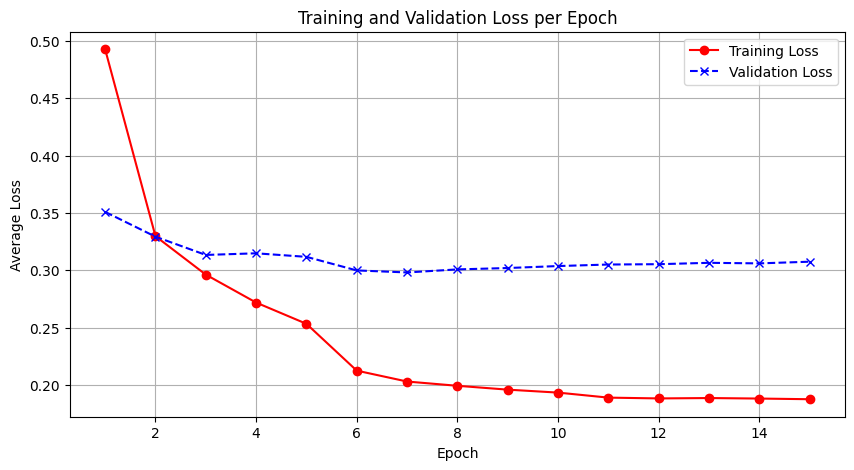

In [ ]:
import torch.optim as optim
import matplotlib.pyplot as plt
import torch
from torch.optim.lr_scheduler import StepLR

# Construct an optimizer
params = [p for p in model.parameters() if p.requires_grad]
optimizer = optim.SGD(params, lr=0.005, momentum=0.9, weight_decay=0.0005)

# --- 1. Learning Rate Scheduler ---
# Reduce learning rate by a factor of 0.1 every 5 epochs
lr_scheduler = StepLR(optimizer, step_size=5, gamma=0.1)

num_epochs = 15
print("Starting training loop on GPU...")

train_losses = []
val_losses = []

# --- 2. Early Stopping Tracker ---
best_val_loss = float('inf')

# --- 3. Gradient Accumulation ---
accumulation_steps = 2 # Effective batch size = DataLoader batch_size (4) * 2 = 8

for epoch in range(num_epochs):
    # --- TRAINING ---
    model.train() # Set the model to training mode
    epoch_train_loss = 0

    optimizer.zero_grad() # Initialize gradients before loop

    for i, (images, targets) in enumerate(train_loader):
        images = list(image.to(device) for image in images)
        targets = [{k: v.to(device) for k, v in t.items()} for t in targets]

        # Forward pass
        loss_dict = model(images, targets)
        losses = sum(loss for loss in loss_dict.values())

        # Normalize the loss based on accumulation steps
        losses = losses / accumulation_steps

        # Backward pass
        losses.backward()

        # Optimizer step only after accumulation_steps
        if (i + 1) % accumulation_steps == 0 or (i + 1) == len(train_loader):
            optimizer.step()
            optimizer.zero_grad()

        # Add real loss value for tracking
        epoch_train_loss += (losses.item() * accumulation_steps)

        if i % 50 == 0:
            print(f"Epoch [{epoch+1}/{num_epochs}], Step [{i}/{len(train_loader)}], Train Loss: {losses.item() * accumulation_steps:.4f}")

    avg_train_loss = epoch_train_loss / len(train_loader)
    train_losses.append(avg_train_loss)

    # --- VALIDATION ---
    epoch_val_loss = 0
    with torch.no_grad():
        for images, targets in val_loader:
            images = list(image.to(device) for image in images)
            targets = [{k: v.to(device) for k, v in t.items()} for t in targets]

            loss_dict = model(images, targets)
            losses = sum(loss for loss in loss_dict.values())
            epoch_val_loss += losses.item()

    avg_val_loss = epoch_val_loss / len(val_loader)
    val_losses.append(avg_val_loss)

    print(f"\nEpoch {epoch+1} finished. Avg Train Loss: {avg_train_loss:.4f} | Avg Val Loss: {avg_val_loss:.4f}")

    # --- 4. Early Stopping Logic ---
    if avg_val_loss < best_val_loss:
        best_val_loss = avg_val_loss
        print(f"--> Saved new best model with Validation Loss: {best_val_loss:.4f}")
        torch.save(model.state_dict(), 'best_model.pth')
    print("-" * 50)

    # Step the learning rate scheduler
    lr_scheduler.step()

print("Training loop completed!")

# --- Plot Training & Validation Curve ---
plt.figure(figsize=(10, 5))
plt.plot(range(1, num_epochs + 1), train_losses, marker='o', linestyle='-', color='r', label='Training Loss')
plt.plot(range(1, num_epochs + 1), val_losses, marker='x', linestyle='--', color='b', label='Validation Loss')
plt.title('Training and Validation Loss per Epoch')
plt.xlabel('Epoch')
plt.ylabel('Average Loss')
plt.legend()
plt.grid(True)
plt.show()

## Step 5: Inference on Validation Data
We passed a random image from our dataset through the trained model and plotted the predicted bounding boxes. This provides a quick visual sanity check to see if the model has actually learned to detect and localize objects accurately after training.

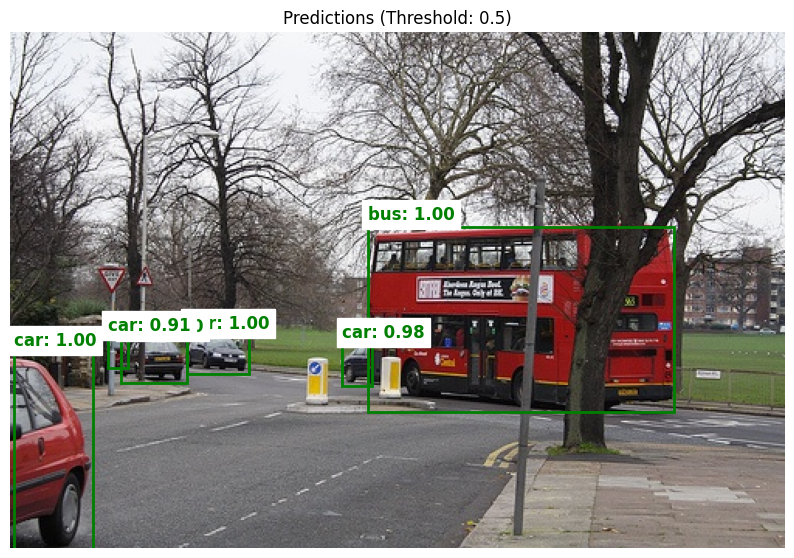

In [ ]:
import torchvision.transforms.v2 as v2
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import random
import torch

# Put the model in evaluation mode
model.eval()

# Select a random image from the dataset
idx = random.randint(0, len(voc_dataset) - 1)
img, target = voc_dataset[idx]

# Transform the image for the model
# We use a simple transform here because get_transform() expects bounding boxes targets
inference_transform = v2.Compose([
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True)
])
img_tensor = inference_transform(img).unsqueeze(0).to(device)  # Add batch dimension and move to device

# Run inference
with torch.no_grad():
    predictions = model(img_tensor)

# Extract predictions
pred_boxes = predictions[0]['boxes'].cpu().numpy()
pred_labels = predictions[0]['labels'].cpu().numpy()
pred_scores = predictions[0]['scores'].cpu().numpy()

# Filter out low-confidence predictions
threshold = 0.5
keep = pred_scores >= threshold
pred_boxes = pred_boxes[keep]
pred_labels = pred_labels[keep]
pred_scores = pred_scores[keep]

# Reverse mapping from ID to class name (using val_dataset)
idx_to_class = {v: k for k, v in val_dataset.class_to_idx.items()}

# Visualize
fig, ax = plt.subplots(1, figsize=(10, 10))
ax.imshow(img)

for box, label, score in zip(pred_boxes, pred_labels, pred_scores):
    xmin, ymin, xmax, ymax = box
    width, height = xmax - xmin, ymax - ymin
    class_name = idx_to_class.get(label, f"Class {label}")

    # Draw bounding box
    rect = patches.Rectangle((xmin, ymin), width, height, linewidth=2, edgecolor='g', facecolor='none')
    ax.add_patch(rect)

    # Add label and score
    label_text = f"{class_name}: {score:.2f}"
    ax.text(xmin, ymin - 5, label_text, color='green', fontsize=12, weight='bold', backgroundcolor='white')

plt.title(f"Predictions (Threshold: {threshold})")
plt.axis('off')
plt.show()

## Step 6: Testing on Custom Images
We added a widget to upload local images and run them through our model. The true test of a machine learning model is how well it generalizes to completely unseen, real-world data outside of its original dataset.

Please upload an image file:


Saving images.jpeg to images.jpeg
Processing uploaded image: images.jpeg


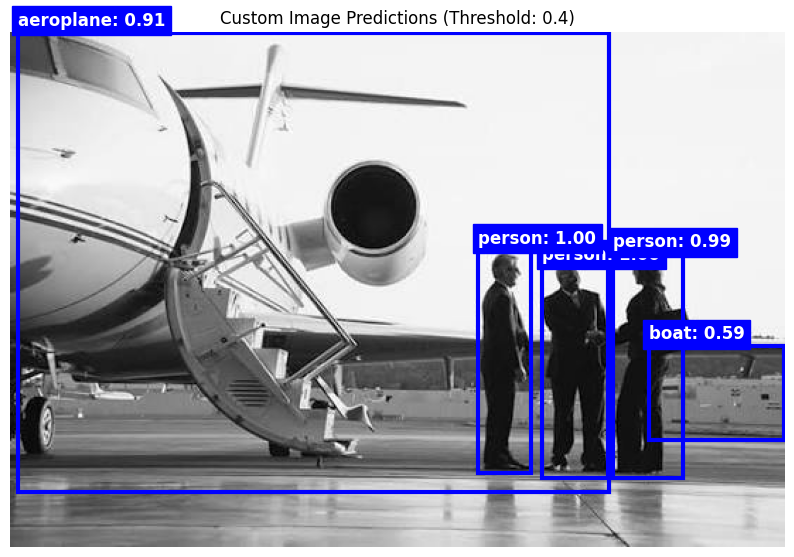

In [ ]:
from google.colab import files
from PIL import Image
import io
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import torch
import torchvision.transforms.v2 as v2

# Prompt user to upload an image
print("Please upload an image file:")
uploaded = files.upload()

if not uploaded:
    print("No image uploaded. Please run the cell again and select an image.")
else:
    # Get the first uploaded file name
    img_name = list(uploaded.keys())[0]
    print(f"Processing uploaded image: {img_name}")
    custom_img = Image.open(io.BytesIO(uploaded[img_name])).convert("RGB")

    # Transform the image for the model
    inference_transform = v2.Compose([
        v2.ToImage(),
        v2.ToDtype(torch.float32, scale=True)
    ])
    img_tensor = inference_transform(custom_img).unsqueeze(0).to(device)

    # Run inference
    model.eval()
    with torch.no_grad():
        predictions = model(img_tensor)

    # Extract predictions
    pred_boxes = predictions[0]['boxes'].cpu().numpy()
    pred_labels = predictions[0]['labels'].cpu().numpy()
    pred_scores = predictions[0]['scores'].cpu().numpy()

    # Filter out low-confidence predictions
    threshold = 0.4
    keep = pred_scores >= threshold
    pred_boxes = pred_boxes[keep]
    pred_labels = pred_labels[keep]
    pred_scores = pred_scores[keep]

    # Get class names mapping
    idx_to_class = {v: k for k, v in val_dataset.class_to_idx.items()}

    # Visualize
    fig, ax = plt.subplots(1, figsize=(10, 10))
    ax.imshow(custom_img)

    for box, label, score in zip(pred_boxes, pred_labels, pred_scores):
        xmin, ymin, xmax, ymax = box
        width, height = xmax - xmin, ymax - ymin
        class_name = idx_to_class.get(label, f"Class {label}")

        # Draw bounding box
        rect = patches.Rectangle((xmin, ymin), width, height, linewidth=3, edgecolor='b', facecolor='none')
        ax.add_patch(rect)

        # Add label and score
        label_text = f"{class_name}: {score:.2f}"
        ax.text(xmin, ymin - 5, label_text, color='white', fontsize=12, weight='bold', backgroundcolor='blue')

    plt.title(f"Custom Image Predictions (Threshold: {threshold})")
    plt.axis('off')
    plt.show()

## Step 7: Saving and Loading the Model
We demonstrated how to initialize a fresh model and load the saved `best_model.pth` weights. In a real-world scenario, training and inference happen in separate stages. This step proves we can successfully deploy our trained weights later without needing to rerun the training loop.

In [ ]:
import torch
import torchvision.transforms.v2 as v2
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# 1. Initialize a fresh model using the function we defined earlier
loaded_model = get_model(num_classes=21)

# 2. Load the saved weights (map_location ensures it loads correctly on CPU or GPU)
loaded_model.load_state_dict(torch.load('best_model.pth', map_location=device, weights_only=True))

# 3. Move model to the appropriate device and set to evaluation mode
loaded_model.to(device)
loaded_model.eval()
print("Saved model ('best_model.pth') loaded successfully!")

# 4. Run inference on a specific image
image_path = '/content/Screenshot 2026-10-23 at 17.59.45.png'

try:
    test_img = Image.open(image_path).convert("RGB")

    # Prepare the image
    inference_transform = v2.Compose([
        v2.ToImage(),
        v2.ToDtype(torch.float32, scale=True)
    ])
    img_tensor = inference_transform(test_img).unsqueeze(0).to(device)

    # Predict
    with torch.no_grad():
        predictions = loaded_model(img_tensor)

    # Extract and filter predictions
    pred_boxes = predictions[0]['boxes'].cpu().numpy()
    pred_labels = predictions[0]['labels'].cpu().numpy()
    pred_scores = predictions[0]['scores'].cpu().numpy()

    threshold = 0.4
    keep = pred_scores >= threshold
    pred_boxes = pred_boxes[keep]
    pred_labels = pred_labels[keep]
    pred_scores = pred_scores[keep]

    # Visualize
    idx_to_class = {v: k for k, v in val_dataset.class_to_idx.items()}
    fig, ax = plt.subplots(1, figsize=(10, 10))
    ax.imshow(test_img)

    for box, label, score in zip(pred_boxes, pred_labels, pred_scores):
        xmin, ymin, xmax, ymax = box
        width, height = xmax - xmin, ymax - ymin
        class_name = idx_to_class.get(label, f"Class {label}")

        rect = patches.Rectangle((xmin, ymin), width, height, linewidth=3, edgecolor='red', facecolor='none')
        ax.add_patch(rect)
        ax.text(xmin, ymin - 5, f"{class_name}: {score:.2f}", color='white', fontsize=12, weight='bold', backgroundcolor='red')

    plt.title(f"Saved Model Predictions (Threshold: {threshold})")
    plt.axis('off')
    plt.show()
except FileNotFoundError:
    print(f"Could not find {image_path}. Please update the path to a valid image.")